# UrbanHub - Personne 3 : Pollution Atmosphérique OpenAQ & Analyse Croisée

**Responsable :** Personne 3 (Flux IoT & Analyse Croisée)  
**Périmètre :** Ingestion des capteurs OpenAQ v3, contrôle et normalisation des unités, raffinement Bronze ➔ Silver ➔ Gold, réponses aux questions métier pollution et pilotage de la jointure multi-sources.  
**Référentiel des villes :** Paris, Lyon, Lille (cf. `config/cities.yml`).  
**Architecture Data Lake :** MinIO (S3) local avec architecture médaillon :
- **Bronze :** `bronze/openaq/city=<city_id>/year=YYYY/month=MM/day=DD/sensor_<id>_<HHMMSS>.json`
- **Silver :** `silver/pollution/year=YYYY/month=MM/pollution_sensors.parquet`
- **Gold :** `gold/kpis/pollution_hourly.parquet`, `gold/kpis/city_hourly.parquet`, `gold/kpis/pollution_summary.json`


In [1]:
# 1. Configuration et imports
import os
import sys
import io
import json
import time
from datetime import datetime, timezone, timedelta
from pathlib import Path
import yaml
import requests
import pandas as pd
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from minio import Minio
from minio.versioningconfig import VersioningConfig, ENABLED
from minio.error import S3Error
from dotenv import load_dotenv

# Style des visualisations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 10

# Résolution de la racine du projet et ajout au sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

if (PROJECT_ROOT / ".env").exists():
    load_dotenv(PROJECT_ROOT / ".env", override=True)

with open(PROJECT_ROOT / "config" / "cities.yml", "r", encoding="utf-8") as f:
    CITIES = yaml.safe_load(f).get("cities", [])

print("[OK] Configuration chargée :")
for c in CITIES:
    print(f"  - {c['name']} (ID: {c['id']}, Coords: {c['latitude']}, {c['longitude']})")


[OK] Configuration chargée :
  - Paris (ID: paris, Coords: 48.8566, 2.3522)
  - Lyon (ID: lyon, Coords: 45.764, 4.8357)
  - Lille (ID: lille, Coords: 50.6292, 3.0573)


In [2]:
# 2. Initialisation idempotente du Data Lake S3 (MinIO)
def init_datalake():
    endpoint = os.getenv("MINIO_ENDPOINT", "localhost:9000")
    access_key = os.getenv("MINIO_ACCESS_KEY", "minioadmin")
    secret_key = os.getenv("MINIO_SECRET_KEY", "minioadmin123")
    secure = os.getenv("MINIO_SECURE", "false").lower() == "true"
    
    client = Minio(endpoint, access_key=access_key, secret_key=secret_key, secure=secure)
    buckets = [
        os.getenv("MINIO_BUCKET_BRONZE", "bronze"),
        os.getenv("MINIO_BUCKET_SILVER", "silver"),
        os.getenv("MINIO_BUCKET_GOLD", "gold"),
    ]
    for b in buckets:
        if not client.bucket_exists(b):
            client.make_bucket(b)
            print(f"Bucket '{b}' créé.")
        else:
            print(f"Bucket '{b}' actif.")
            
    # Versioning activé sur Bronze pour auditabilité
    bronze_bucket = os.getenv("MINIO_BUCKET_BRONZE", "bronze")
    try:
        client.set_bucket_versioning(bronze_bucket, VersioningConfig(ENABLED))
        print(f"Versioning activé sur '{bronze_bucket}'.")
    except S3Error as exc:
        print(
            f"[ATTENTION] Versioning non modifié sur '{bronze_bucket}' "
            f"({exc.code}: {exc.message}). Le reste du pipeline peut continuer."
        )
    return client

minio_client = init_datalake()


Bucket 'urbanhub-bronze' actif.


Bucket 'urbanhub-silver' actif.
Bucket 'urbanhub-gold' actif.


[ATTENTION] Versioning non modifié sur 'urbanhub-bronze' (AccessDenied: Access Denied). Le reste du pipeline peut continuer.


## Étape 1 : Exploration OpenAQ v3 & Matrice Ville × Polluant

L'API OpenAQ v3 (`https://api.openaq.org/v3`) requiert une clé passée dans le header `X-API-Key`.  
Nous découvrons les stations actives situées dans un rayon de 25 km autour de chaque ville et vérifions la présence des 5 polluants cibles :
- **PM2.5** (Particules fines < 2.5 µm)
- **PM10** (Particules respirables < 10 µm)
- **NO2** (Dioxyde d'azote - marqueur de trafic routier)
- **O3** (Ozone - polluant secondaire photochimique estival)
- **CO** (Monoxyde de carbone - combustion incomplète)


In [3]:
# 3. Exploration des capteurs et matrice Ville x Polluant
from src.openaq_pipeline import OpenAQClient, discover_city_sensors, TARGET_POLLUTANTS

aq_client = OpenAQClient()
matrix, catalog = discover_city_sensors(aq_client, CITIES, radius_m=25000)

print(f"\nTotal de capteurs cibles répertoriés : {len(catalog)}")

# Construction du tableau de synthèse de la matrice
matrix_rows = []
for cid, m in matrix.items():
    row = {
        "Ville": m["city_name"],
        "Stations détectées (25km)": m["total_locations"],
        "PM2.5": "Dispo" if "pm25" in m["pollutants_found"] else "Absent",
        "PM10": "Dispo" if "pm10" in m["pollutants_found"] else "Absent",
        "NO2": "Dispo" if "no2" in m["pollutants_found"] else "Absent",
        "O3": "Dispo" if "o3" in m["pollutants_found"] else "Absent",
        "CO": "Dispo" if "co" in m["pollutants_found"] else "Absent",
    }
    matrix_rows.append(row)

df_matrix = pd.DataFrame(matrix_rows)
display(df_matrix)



Total de capteurs cibles répertoriés : 149


,Ville,Stations détectées (25km),PM2.5,PM10,NO2,O3,CO
0,Paris,>30,Dispo,Dispo,Dispo,Dispo,Dispo
1,Lyon,20,Dispo,Dispo,Dispo,Dispo,Dispo
2,Lille,18,Dispo,Dispo,Dispo,Dispo,Dispo


## Étape 2 : Ingestion en zone Bronze (Flux IoT partitionné Hive)

Les payloads bruts sont archivés dans `bronze/openaq/` selon le partitionnement Hive recommandé :  
`openaq/city=<city_id>/year=YYYY/month=MM/day=DD/sensor_<sensor_id>_<time>.json`

Ce stockage brut conserve l'intégralité des métadonnées de l'API (flagInfo, période de mesure, coordonnées géographiques, unités déclarées).


In [4]:
# 4. Ingestion Bronze des séries temporelles récentes
from src.openaq_pipeline import ingest_openaq_to_bronze

# Ingestion contrôlée des mesures IoT
bronze_keys = ingest_openaq_to_bronze(minio_client, aq_client, catalog, max_sensors_per_pollutant=2)
print(f"\n[OK] Total d'objets ingérés ou mis à jour dans Bronze : {len(bronze_keys)}")

# Inspection d'un objet Bronze
if bronze_keys:
    sample_key = bronze_keys[0]
    bronze_bucket = os.getenv("MINIO_BUCKET_BRONZE", "bronze")
    sample_obj = minio_client.get_object(bronze_bucket, sample_key)
    sample_data = json.loads(sample_obj.read().decode("utf-8"))
    sample_obj.close()
    sample_obj.release_conn()
    print(f"\nExemple de payload Bronze ({sample_key}) :")
    print("Capteur :", sample_data["sensor_metadata"]["pollutant"], f"(ID: {sample_data['sensor_metadata']['sensor_id']})")
    print("Nombre de relevés bruts :", len(sample_data["response"]["results"]))
    if sample_data["response"]["results"]:
        print("Premier relevé :", sample_data["response"]["results"][0])


Début de l'ingestion Bronze pour 28 capteurs sélectionnés...


[OK] Total Bronze : 22 objets sauvegardés dans urbanhub-bronze.

[OK] Total d'objets ingérés ou mis à jour dans Bronze : 22

Exemple de payload Bronze (openaq/city=paris/year=2026/month=11/day=19/sensor_5620_153347.json) :
Capteur : no2 (ID: 5620)
Nombre de relevés bruts : 325
Premier relevé : {'value': 24.5, 'flagInfo': {'hasFlags': False}, 'parameter': {'id': 5, 'name': 'no2', 'units': 'µg/m³', 'displayName': None}, 'period': {'label': 'raw', 'interval': '01:00:00', 'datetimeFrom': {'utc': '2026-11-05T05:00:00Z', 'local': '2026-11-05T06:00:00+01:00'}, 'datetimeTo': {'utc': '2026-11-05T06:00:00Z', 'local': '2026-11-05T07:00:00+01:00'}}, 'coordinates': None, 'summary': None, 'coverage': {'expectedCount': 1, 'expectedInterval': '01:00:00', 'observedCount': 1, 'observedInterval': '01:00:00', 'percentComplete': 100.0, 'percentCoverage': 100.0, 'datetimeFrom': {'utc': '2026-11-05T05:00:00Z', 'local': '2026-11-05T06:00:00+01:00'}, 'datetimeTo': {'utc': '2026-11-05T06:00:00Z', 'local': '2026

## Étape 3 : Raffinage en zone Silver (Parquet, Contrôle & Harmonisation des Unités)

### Contrat de qualité Silver :
1. **Contrôle et conversion des unités :**  
   Les polluants particulaires et gazeux sont tous normalisés en **`µg/m³`**. Si un capteur rapporte en `ppm` ou `ppb`, la conversion stœchiométrique à 20°C et 1013 hPa est appliquée (ex: NO2 $1\text{ ppm} = 1880\text{ µg/m³}$, O3 $1\text{ ppm} = 1960\text{ µg/m³}$, CO $1\text{ ppm} = 1145\text{ µg/m³}$).
2. **Filtrage des anomalies instrumentales :**  
   - Suppression des valeurs négatives ($< 0$) issues des dérives du zéro des capteurs électrochimiques ou optiques.
   - Suppression des valeurs aberrantes extrêmes (ex: $> 5000\text{ µg/m³}$ pour les particules).
3. **Déduplication :** Clé unique `(sensor_id, timestamp_utc)`.
4. **Schéma Parquet PyArrow :** Écrit en mémoire avec compression Snappy et métadonnées d'audit (`date_traitement_utc`).


In [5]:
# 5. Nettoyage Silver et écriture Parquet
from src.openaq_pipeline import clean_and_transform_to_silver

df_silver = clean_and_transform_to_silver(minio_client)
print(f"\n[OK] Table Silver chargée : {len(df_silver)} observations nettoyées.")
display(df_silver.head())

print("\nSchéma et types de données Silver :")
print(df_silver.dtypes)

print("\nContrôle des unités présentes après transformation :")
display(df_silver.groupby(["pollutant", "unit"]).size().reset_index(name="nb_mesures"))


Déduplication : 65631 doublons supprimés sur 71360 lignes.


Silver sauvegardé : urbanhub-silver/pollution/pollution_france.parquet (5729 lignes)

[OK] Table Silver chargée : 5729 observations nettoyées.


,sensor_id,location_id,location_name,locality,pollutant,timestamp_utc,latitude,longitude,value,unit,city_id,city_name,date_traitement_utc
0,24859,3767,Harnes Serres,HARNES,no2,2026-11-05 05:00:00+00:00,50.44914,2.9,10.1,µg/m³,lille,Lille,2026-11-19T15:34:17.722946+00:00
1,24859,3767,Harnes Serres,HARNES,no2,2026-11-05 10:00:00+00:00,50.44914,2.9,11.2,µg/m³,lille,Lille,2026-11-19T15:34:17.722946+00:00
2,24859,3767,Harnes Serres,HARNES,no2,2026-11-05 11:00:00+00:00,50.44914,2.9,8.0,µg/m³,lille,Lille,2026-11-19T15:34:17.722946+00:00
3,24859,3767,Harnes Serres,HARNES,no2,2026-11-05 12:00:00+00:00,50.44914,2.9,6.7,µg/m³,lille,Lille,2026-11-19T15:34:17.722946+00:00
4,24859,3767,Harnes Serres,HARNES,no2,2026-11-05 13:00:00+00:00,50.44914,2.9,8.3,µg/m³,lille,Lille,2026-11-19T15:34:17.722946+00:00



Schéma et types de données Silver :
sensor_id                              str
location_id                          int64
location_name                          str
locality                               str
pollutant                              str
timestamp_utc          datetime64[us, UTC]
latitude                           float64
longitude                          float64
value                              float64
unit                                   str
city_id                                str
city_name                              str
date_traitement_utc                    str
dtype: object

Contrôle des unités présentes après transformation :


,pollutant,unit,nb_mesures
0,co,µg/m³,318
1,no2,µg/m³,1932
2,o3,µg/m³,1601
3,pm10,µg/m³,944
4,pm25,µg/m³,934


## Étape 4 : Indicateurs Gold & Réponses aux Questions Métier

### Question Métier 1 : Quelles zones présentent les niveaux de pollution les plus élevés ?
Nous identifions les stations enregistrant les concentrations moyennes et les pics les plus intenses par polluant.


Gold sauvegardé : urbanhub-gold/kpis/pollution_hourly.parquet (3736 lignes)


Résumé JSON sauvegardé : urbanhub-gold/kpis/pollution_summary.json
Top 10 des stations les plus exposées par polluant :


,city_name,location_name,pollutant,unit,concentration_moyenne,pic_maximal,nb_mesures
11,Lyon,Lyon Périphérique,co,µg/m³,283.091195,1067.0,318
12,Lyon,Lyon Périphérique,no2,µg/m³,32.744969,79.7,318
19,Paris,Place de l'Opéra,no2,µg/m³,29.271385,70.5,325
3,Lille,Roubaix Serres,no2,µg/m³,27.244923,77.8,325
15,Paris,PARIS 18eme,no2,µg/m³,25.300000,72.5,327
7,Lyon,LYON Centre,no2,µg/m³,17.925237,47.4,317
1,Lille,Harnes Serres,no2,µg/m³,15.450938,54.7,320
8,Lyon,LYON Centre,o3,µg/m³,31.563023,73.1,311
21,Paris,VITRY-SUR-SEINE,o3,µg/m³,30.918944,80.4,322
16,Paris,PARIS 18eme,o3,µg/m³,29.402141,78.5,327


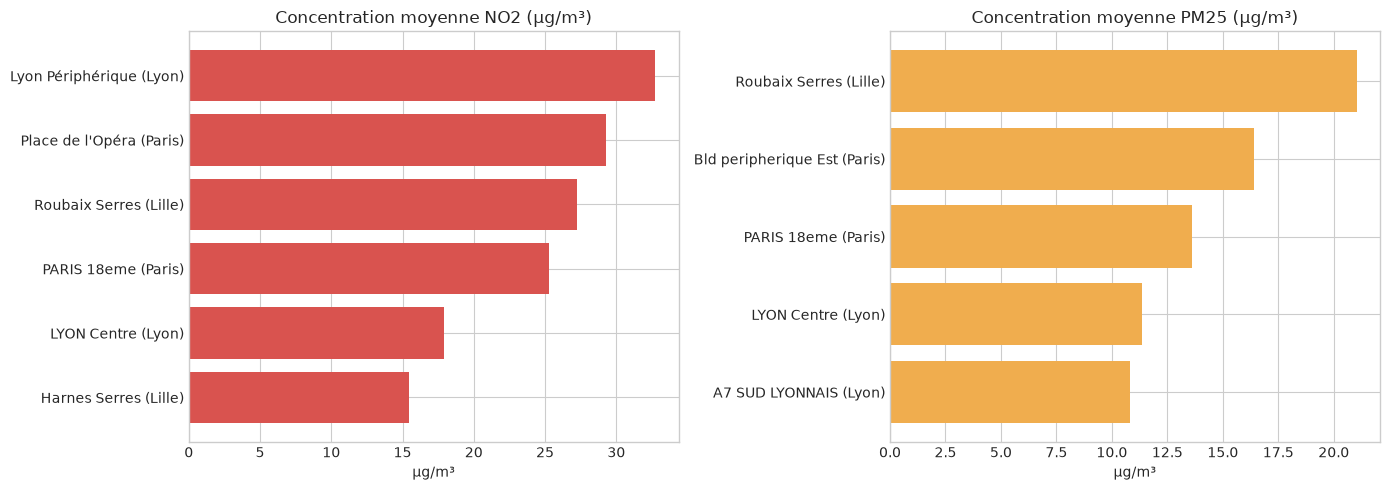

In [6]:
# 6. Question Métier 1 : Zones les plus polluées (Top stations)
from src.openaq_pipeline import compute_gold_pollution

hourly_gold, zones_ranking, diurnal_profile, df_dominance, anomalies = compute_gold_pollution(minio_client, df_silver)

print("Top 10 des stations les plus exposées par polluant :")
display(zones_ranking.head(10))

# Visualisation comparative des zones pour le NO2 et PM2.5
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, target_pol in enumerate(["no2", "pm25"]):
    sub_df = zones_ranking[zones_ranking["pollutant"] == target_pol].head(7)
    if not sub_df.empty:
        axes[idx].barh(sub_df["location_name"] + " (" + sub_df["city_name"] + ")", sub_df["concentration_moyenne"], color="#d9534f" if target_pol=="no2" else "#f0ad4e")
        axes[idx].set_title(f"Concentration moyenne {target_pol.upper()} (µg/m³)")
        axes[idx].set_xlabel("µg/m³")
        axes[idx].invert_yaxis()
plt.tight_layout()
plt.show()


### Question Métier 2 : Existe-t-il une variation journalière de la pollution ?

Nous modélisons le profil diurne horaire (00h00 à 23h00 UTC) pour chaque polluant afin d'observer :
- Les **pics de trafic** matinaux (7h-9h) et vespéraux (17h-19h) sur le **NO2** et le **CO**.
- Le **pic photochimique solaire** de l'après-midi (14h-16h) sur l'**Ozone (O3)**.


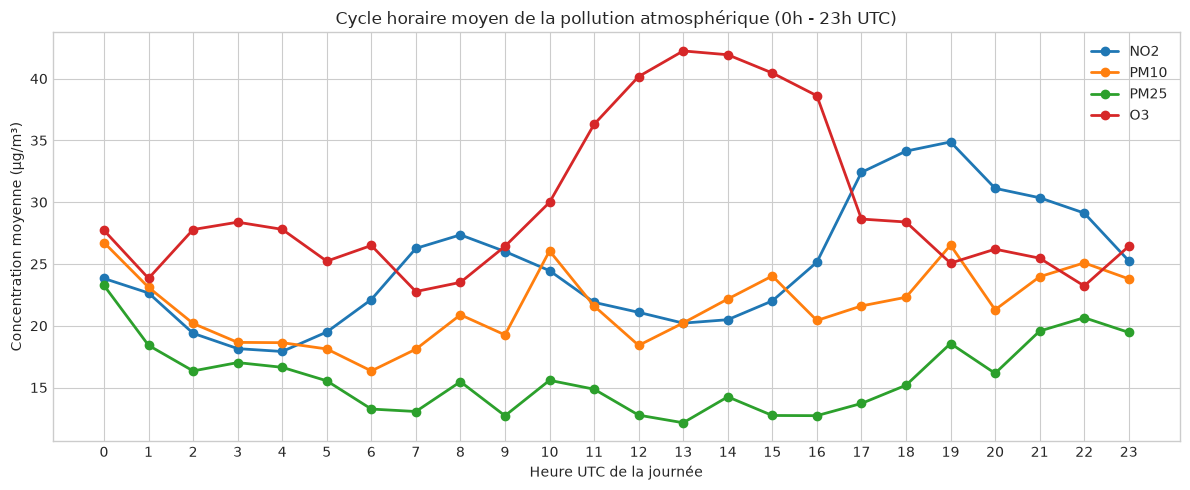

In [7]:
# 7. Question Métier 2 : Variations journalières (Cycle diurne)
fig, ax = plt.subplots(figsize=(12, 5))

for pol in ["no2", "pm10", "pm25", "o3"]:
    pol_diurnal = diurnal_profile[diurnal_profile["pollutant"] == pol].groupby("heure_du_jour")["valeur_moyenne"].mean()
    if not pol_diurnal.empty:
        ax.plot(pol_diurnal.index, pol_diurnal.values, marker="o", label=pol.upper(), linewidth=2)

ax.set_title("Cycle horaire moyen de la pollution atmosphérique (0h - 23h UTC)")
ax.set_xlabel("Heure UTC de la journée")
ax.set_ylabel("Concentration moyenne (µg/m³)")
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.show()


### Question Métier 3 : Quels polluants sont les plus dominants dans la ville étudiée ?

> [ATTENTION] **Précision méthodologique essentielle :**  
> On ne peut pas comparer directement les microgrammes de gaz légers comme le CO aux particules fines pour désigner le « dominant ».  
> Pour établir une comparaison rigoureuse, nous calculons le **ratio de dépassement par rapport aux seuils sanitaires de référence de l'OMS (Lignes directrices 24h)** :
> - PM2.5 : 15 µg/m³
> - PM10 : 45 µg/m³
> - NO2 : 25 µg/m³
> - O3 : 100 µg/m³ (seuil 8h)
> - CO : 4000 µg/m³


Classement de la dominance des polluants par rapport aux seuils OMS :


,pollutant,seuil_ref_oms,moyenne_observee,ratio_sur_seuil,pct_mesures_au_dessus_seuil
4,pm25,15.0,15.42,1.03,41.0
1,no2,25.0,24.68,0.99,44.1
3,pm10,45.0,20.72,0.46,5.0
2,o3,100.0,29.49,0.29,0.0
0,co,4000.0,283.09,0.07,0.0


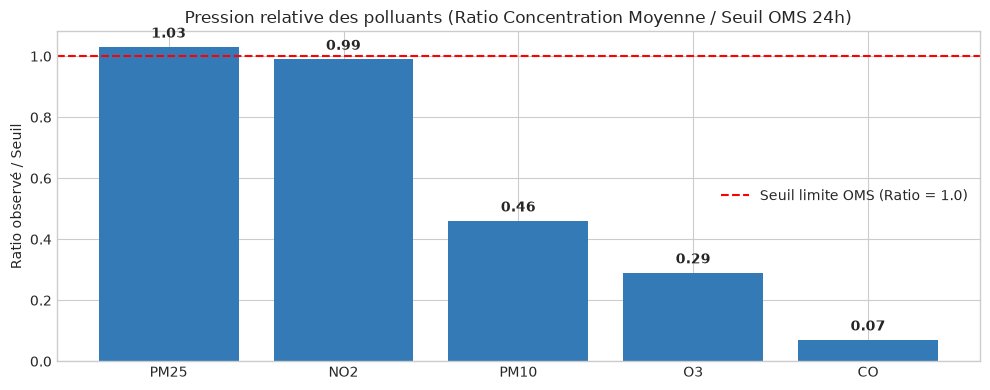

In [8]:
# 8. Question Métier 3 : Dominance relative par rapport aux recommandations sanitaires OMS
print("Classement de la dominance des polluants par rapport aux seuils OMS :")
display(df_dominance)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(df_dominance["pollutant"].str.upper(), df_dominance["ratio_sur_seuil"], color="#337ab7")
ax.axhline(1.0, color="red", linestyle="--", linewidth=1.5, label="Seuil limite OMS (Ratio = 1.0)")
ax.set_title("Pression relative des polluants (Ratio Concentration Moyenne / Seuil OMS 24h)")
ax.set_ylabel("Ratio observé / Seuil")
ax.legend()

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.2f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


### Question Métier 4 : Peut-on identifier des épisodes de pollution anormale ?

Nous utilisons le seuil empirique du **95e percentile** par ville et par polluant pour détecter les pics de concentration d'alerte.


[ALERTE] Nombre total d'anomalies détectées (> P95) : 293


,city_id,location,pollutant,timestamp_utc,valeur,seuil_p95
0,lille,Harnes Serres,no2,2026-11-13T18:00:00+00:00,54.7,44.48
1,lille,Harnes Serres,no2,2026-11-13T19:00:00+00:00,46.9,44.48
2,lille,Harnes Serres,no2,2026-11-16T19:00:00+00:00,52.3,44.48
3,lille,Harnes Serres,no2,2026-11-16T20:00:00+00:00,44.6,44.48
4,lille,Roubaix Serres,no2,2026-11-05T17:00:00+00:00,46.1,44.48
5,lille,Roubaix Serres,no2,2026-11-05T18:00:00+00:00,46.2,44.48
6,lille,Roubaix Serres,no2,2026-11-05T19:00:00+00:00,46.1,44.48
7,lille,Roubaix Serres,no2,2026-11-06T16:00:00+00:00,45.0,44.48
8,lille,Roubaix Serres,no2,2026-11-09T17:00:00+00:00,52.2,44.48
9,lille,Roubaix Serres,no2,2026-11-09T18:00:00+00:00,48.7,44.48


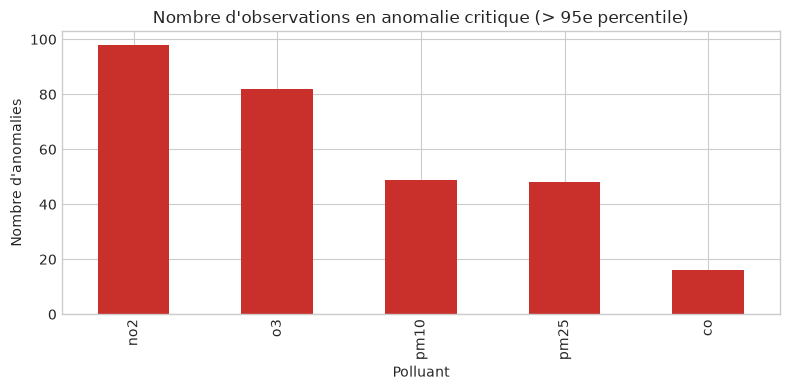

In [9]:
# 9. Question Métier 4 : Détection d'anomalies (> 95e percentile)
df_anom = pd.DataFrame(anomalies)
print(f"[ALERTE] Nombre total d'anomalies détectées (> P95) : {len(df_anom)}")

if not df_anom.empty:
    display(df_anom.head(10))
    
    # Répartition des anomalies par polluant
    fig, ax = plt.subplots(figsize=(8, 4))
    anom_counts = df_anom["pollutant"].value_counts()
    anom_counts.plot(kind="bar", color="#c9302c", ax=ax)
    ax.set_title("Nombre d'observations en anomalie critique (> 95e percentile)")
    ax.set_xlabel("Polluant")
    ax.set_ylabel("Nombre d'anomalies")
    plt.tight_layout()
    plt.show()


## Étape 5 : Analyse Croisée Multi-sources & Diagnostic de Couverture

### Algorithme de Jointure `city_hourly` :
La jointure multi-sources définie dans l'architecture s'appuie sur la clé spatio-temporelle unifiée :  
$$\text{Clé de jointure} = (\text{city\_id}, \text{hour\_utc})$$

### Contrôle des Dépendances & Diagnostic :
En tant que responsable de la jointure croisée, la Personne 3 vérifie la présence des tables Silver/Gold produites par :
- **Personne 1 (Météo NOAA) :** `silver/weather/` ou `gold/kpis/weather_hourly.parquet`
- **Personne 2 (Mobilité CityBikes) :** `silver/mobility/` ou `gold/kpis/mobility_hourly.parquet`

Conformément au contrat de données et à la consigne de gestion des dépendances :  
*« Si les dates ne se recouvrent pas assez ou si les tables sont en cours de construction, publier le diagnostic plutôt qu'interpoler ou fabriquer des données. »*


In [10]:
# 10. Contrôle des dépendances et diagnostic de couverture
from src.openaq_pipeline import check_and_build_cross_analysis

diagnostic, city_hourly = check_and_build_cross_analysis(minio_client, hourly_gold)

print("\nRapport de diagnostic formel pour le groupe et le dashboard :")
print(json.dumps(diagnostic, indent=2, ensure_ascii=False))

print("\nTable Gold préparée pour la Personne 4 (city_hourly) :")
display(city_hourly.head())



Contrôle et fusion multi-sources pour l'analyse croisée :


  Copie mise à jour citybikes/kpis/mobility_hourly.parquet ➔ kpis/mobility_hourly.parquet


  Copie mise à jour citybikes/kpis/mobility_station_latest.parquet ➔ kpis/mobility_station_latest.parquet


  - Source 1 Météo (open-meteo) : Disponible (kpis/weather_hourly.parquet, 181050 lignes)
  - Source 2 Mobilité CityBikes (Personne 2) : Disponible (citybikes/kpis/mobility_hourly.parquet, 3 lignes)
  - Source 3 Pollution OpenAQ (Personne 3) : Disponible (3736 lignes)


Table Gold multi-sources sauvegardée : urbanhub-gold/kpis/city_hourly.parquet (181050 lignes)


Diagnostic de couverture mis à jour : urbanhub-gold/kpis/diagnostic_couverture_croisee.json

Rapport de diagnostic formel pour le groupe et le dashboard :
{
  "date_diagnostic_utc": "2026-11-19T15:35:28.086556+00:00",
  "responsable_croisement": "Personne 3 (Julie)",
  "statut_global": "multi_sources_fusionnees",
  "sources": {
    "meteo_noaa": {
      "statut": "connectee_et_fusionnee",
      "responsable": "Personne 1 (Rémi)",
      "lignes_source": 181050
    },
    "mobilite_citybikes": {
      "statut": "connectee_et_fusionnee",
      "responsable": "Personne 2 (Conanbot)",
      "lignes_source": 3
    },
    "pollution_openaq": {
      "statut": "connectee_et_fusionnee",
      "responsable": "Personne 3 (Julie)",
      "lignes_source": 3736
    }
  },
  "table_croisee": {
    "destination": "gold/kpis/city_hourly.parquet",
    "total_lignes": 181050,
    "repartition_statuts": {
      "meteo_seule": 180080,
      "pollution_et_meteo": 967,
      "complete_3_sources": 3
    },
  

,city_id,hour_utc,pollution_co_ugm3,pollution_no2_ugm3,pollution_o3_ugm3,pollution_pm10_ugm3,pollution_pm25_ugm3,mobility_bikes_available,mobility_free_slots,mobility_stations_count,...,mobility_saturation_rate,mobility_critical_rate,weather_temperature_c,weather_wind_speed_ms,weather_wind_direction_deg,weather_precipitation_mm,weather_visibility_m,weather_pressure_hpa,city_name,statut_jointure
0,lille,2020-01-01 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,0.6,3.18,103.0,0.0,NaN,1032.9,Lille,meteo_seule
1,lille,2020-01-01 01:00:00+00:00,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,0.6,3.20,110.0,0.0,NaN,1032.5,Lille,meteo_seule
2,lille,2020-01-01 02:00:00+00:00,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,0.4,2.90,134.0,0.0,NaN,1032.2,Lille,meteo_seule
3,lille,2020-01-01 03:00:00+00:00,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,0.3,2.94,145.0,0.0,NaN,1031.6,Lille,meteo_seule
4,lille,2020-01-01 04:00:00+00:00,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,-0.2,2.78,150.0,0.0,NaN,1031.1,Lille,meteo_seule


## Analyse croisée : météo et pollution (données réelles)

Cette section remplace l'ancienne simulation : tout est calculé sur la table `city_hourly` construite à l'étape précédente, aux heures où une mesure météo (Open-Meteo) et au moins une mesure de pollution (OpenAQ) existent pour la même ville et la même heure UTC.

Méthode :
- **corrélation de Spearman** (rangs), moins sensible aux valeurs extrêmes que Pearson, calculée seulement si au moins 30 heures sont disponibles ;
- **classes de vitesse de vent** pour visualiser la dispersion ;
- **test de Mann-Whitney** pour comparer les heures avec et sans pluie ;
- les nombres d'heures sont affichés partout : la pollution ne couvre qu'environ deux semaines, les résultats sont donc des tendances et non des lois.

Couverture de city_hourly par statut de jointure :


,heures
statut_jointure,
meteo_seule,180080
pollution_et_meteo,967
complete_3_sources,3



Heures avec météo et pollution : 971 (du 05/11/2026 au 19/11/2026 13:00 UTC)
Heures par ville : {'paris': 327, 'lille': 326, 'lyon': 318}

Corrélation de Spearman (rho) entre météo et polluants :


Météo,Pluie (mm),Pression (hPa),Température (°C),Vent (m/s)
Polluant,,,,
NO2,-0.24,0.48,-0.33,-0.65
O3,0.12,-0.54,0.51,0.71
PM10,-0.22,0.60,-0.54,-0.67
PM2.5,-0.19,0.58,-0.59,-0.67


Nombre d'heures utilisées :


Météo,Pluie (mm),Pression (hPa),Température (°C),Vent (m/s)
Polluant,,,,
NO2,970,970,970,970
O3,964,964,964,964
PM10,742,742,742,742
PM2.5,742,742,742,742


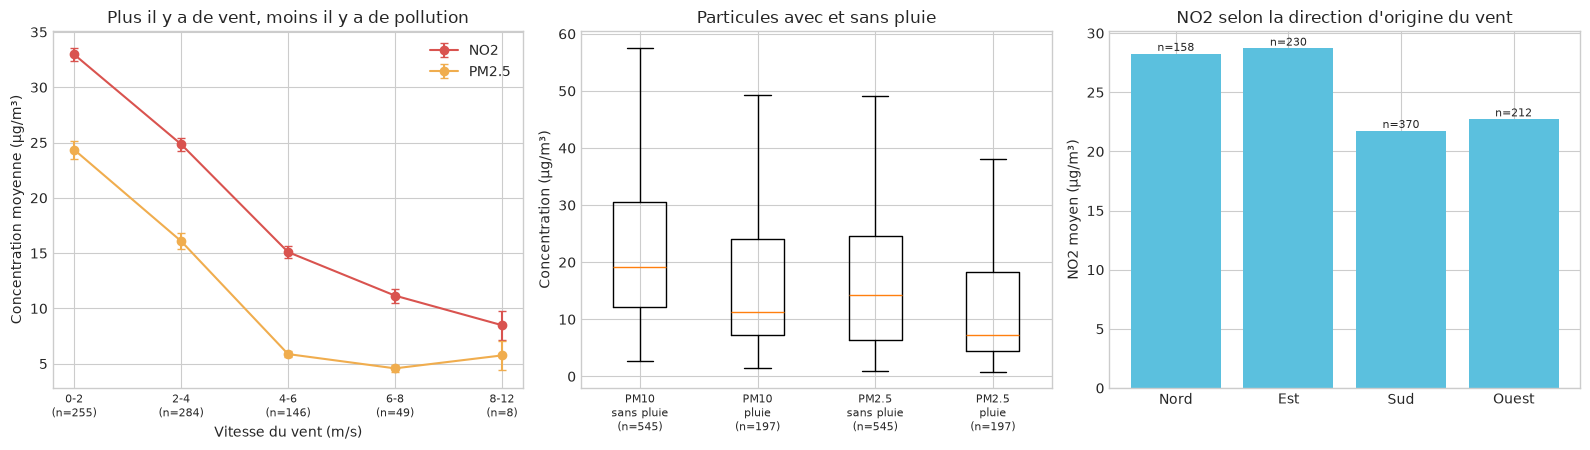


Lecture :
- NO2 et vent : rho = -0.65 sur 970 heures (p = 3.5e-116).
- PM2.5 et vent : rho = -0.67 sur 742 heures (p = 2.7e-97).
- PM10 : médiane 11.3 µg/m³ avec pluie (197 h) contre 19.1 sans pluie (545 h), p = 8.4e-09.
- PM2.5 : médiane 7.3 µg/m³ avec pluie (197 h) contre 14.2 sans pluie (545 h), p = 1.7e-06.

Heures où les trois sources coexistent : 3
[ATTENTION] Moins de 24 heures à trois sources : l'interaction mobilité, pollution et météo ne peut pas être conclue. Laisser tourner la collecte CityBikes puis relancer ce notebook.
[OK] Analyse croisée terminée, tables Gold publiées dans le Data Lake.


In [11]:
# 11. Analyse croisée réelle : météo et pollution
from scipy import stats

POLLUANTS = {"no2": "NO2", "pm25": "PM2.5", "pm10": "PM10", "o3": "O3"}
METEO = {
    "weather_wind_speed_ms": "Vent (m/s)",
    "weather_precipitation_mm": "Pluie (mm)",
    "weather_temperature_c": "Température (°C)",
    "weather_pressure_hpa": "Pression (hPa)",
}
MIN_HEURES = 30

ch = city_hourly.copy()
print("Couverture de city_hourly par statut de jointure :")
display(ch["statut_jointure"].value_counts().rename("heures").to_frame())

cols_pol = [f"pollution_{p}_ugm3" for p in POLLUANTS if f"pollution_{p}_ugm3" in ch]
both = ch.dropna(subset=["weather_temperature_c"]).dropna(subset=cols_pol, how="all").copy()
if both.empty:
    print("[ATTENTION] Aucune heure ne contient à la fois la météo et la pollution : analyse impossible.")
else:
    debut, fin = both["hour_utc"].min(), both["hour_utc"].max()
    print(f"\nHeures avec météo et pollution : {len(both)} (du {debut:%d/%m/%Y} au {fin:%d/%m/%Y %H:%M} UTC)")
    print("Heures par ville :", both["city_id"].value_counts().to_dict())

    # 1. Corrélations de Spearman, avec le nombre d'heures utilisées
    rows = []
    for pol, pol_label in POLLUANTS.items():
        col = f"pollution_{pol}_ugm3"
        if col not in both:
            continue
        for mcol, mlabel in METEO.items():
            sub = both[[col, mcol]].dropna()
            if len(sub) >= MIN_HEURES and sub[mcol].nunique() > 1:
                rho, pval = stats.spearmanr(sub[mcol], sub[col])
                rows.append({"Polluant": pol_label, "Météo": mlabel, "rho": rho, "p": pval, "heures": len(sub)})
    corr = pd.DataFrame(rows)
    if corr.empty:
        print("[ATTENTION] Pas assez d'heures pour calculer des corrélations.")
    else:
        print("\nCorrélation de Spearman (rho) entre météo et polluants :")
        display(corr.pivot(index="Polluant", columns="Météo", values="rho").round(2))
        print("Nombre d'heures utilisées :")
        display(corr.pivot(index="Polluant", columns="Météo", values="heures"))

    # 2. Dispersion par le vent : concentration moyenne par classe de vitesse
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    bins = [0, 2, 4, 6, 8, 12, 40]
    labels = ["0-2", "2-4", "4-6", "6-8", "8-12", ">12"]
    for pol, color in (("no2", "#d9534f"), ("pm25", "#f0ad4e")):
        col = f"pollution_{pol}_ugm3"
        sub = both[["weather_wind_speed_ms", col]].dropna()
        if len(sub) < MIN_HEURES:
            continue
        sub = sub.assign(classe=pd.cut(sub["weather_wind_speed_ms"], bins=bins, labels=labels))
        g = sub.groupby("classe", observed=True)[col].agg(["mean", "sem", "count"])
        axes[0].errorbar(range(len(g)), g["mean"], yerr=g["sem"], marker="o", capsize=3, label=POLLUANTS[pol], color=color)
        axes[0].set_xticks(range(len(g)))
        axes[0].set_xticklabels([f"{i}\n(n={int(n)})" for i, n in zip(g.index, g["count"])], fontsize=8)
    axes[0].set_title("Plus il y a de vent, moins il y a de pollution")
    axes[0].set_xlabel("Vitesse du vent (m/s)")
    axes[0].set_ylabel("Concentration moyenne (µg/m³)")
    axes[0].legend()

    # 3. Effet de la pluie sur les particules
    data, names = [], []
    for pol in ("pm10", "pm25"):
        col = f"pollution_{pol}_ugm3"
        sub = both[[col, "weather_precipitation_mm"]].dropna()
        for label, mask in (("sans pluie", sub["weather_precipitation_mm"] <= 0), ("pluie", sub["weather_precipitation_mm"] > 0)):
            if mask.sum() > 0:
                data.append(sub.loc[mask, col].values)
                names.append(f"{POLLUANTS[pol]}\n{label}\n(n={int(mask.sum())})")
    if data:
        axes[1].boxplot(data, tick_labels=names, showfliers=False)
    axes[1].set_title("Particules avec et sans pluie")
    axes[1].set_ylabel("Concentration (µg/m³)")
    axes[1].tick_params(axis="x", labelsize=8)

    # 4. Direction du vent : NO2 moyen par secteur de 90 degrés
    if "weather_wind_direction_deg" in both:
        sub = both[["weather_wind_direction_deg", "pollution_no2_ugm3"]].dropna()
        if len(sub) >= MIN_HEURES:
            secteurs = pd.cut((sub["weather_wind_direction_deg"] + 45) % 360, [0, 90, 180, 270, 360],
                              labels=["Nord", "Est", "Sud", "Ouest"], right=False)
            g = sub.groupby(secteurs, observed=True)["pollution_no2_ugm3"].agg(["mean", "count"])
            axes[2].bar(g.index.astype(str), g["mean"], color="#5bc0de")
            for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
                axes[2].text(i, m, f"n={int(n)}", ha="center", va="bottom", fontsize=8)
    axes[2].set_title("NO2 selon la direction d'origine du vent")
    axes[2].set_ylabel("NO2 moyen (µg/m³)")
    plt.tight_layout()
    plt.show()

    # 5. Lecture des résultats, calculée sur les données
    print("\nLecture :")
    for pol in ("no2", "pm25"):
        col = f"pollution_{pol}_ugm3"
        sub = both[["weather_wind_speed_ms", col]].dropna()
        if len(sub) >= MIN_HEURES:
            rho, pval = stats.spearmanr(sub["weather_wind_speed_ms"], sub[col])
            print(f"- {POLLUANTS[pol]} et vent : rho = {rho:+.2f} sur {len(sub)} heures (p = {pval:.1e}).")
    for pol in ("pm10", "pm25"):
        col = f"pollution_{pol}_ugm3"
        sub = both[[col, "weather_precipitation_mm"]].dropna()
        pluie, sec = sub.loc[sub["weather_precipitation_mm"] > 0, col], sub.loc[sub["weather_precipitation_mm"] <= 0, col]
        if len(pluie) >= 10 and len(sec) >= 10:
            _, pval = stats.mannwhitneyu(pluie, sec, alternative="two-sided")
            print(f"- {POLLUANTS[pol]} : médiane {pluie.median():.1f} µg/m³ avec pluie ({len(pluie)} h) contre {sec.median():.1f} sans pluie ({len(sec)} h), p = {pval:.2g}.")

# 6. Interaction mobilité, pollution et météo
triple = ch[ch["statut_jointure"].eq("complete_3_sources")] if "statut_jointure" in ch else ch.iloc[0:0]
print(f"\nHeures où les trois sources coexistent : {len(triple)}")
if len(triple) < 24:
    print("[ATTENTION] Moins de 24 heures à trois sources : l'interaction mobilité, pollution et météo ne peut pas être conclue. "
          "Laisser tourner la collecte CityBikes puis relancer ce notebook.")
print("[OK] Analyse croisée terminée, tables Gold publiées dans le Data Lake.")